In [31]:
import pymovements as pm


# Inspecting the GECO and SWOW datasets

Loads the outputs of `scripts/01_load_geco.py` and `scripts/02_geco_swow_coverage.py` (run those first) and
gives a quick visual sanity check:

1. GECO reading measures - distributions, word-length effect, per-participant means
2. GECO x SWOW cross-reference - coverage per POS, along the text, and for a single trial
3. The SWOW-EN network - degree distributions

In [32]:
import sys
sys.path.insert(0, "src")

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from semfields.eyetracking import geco
from semfields.network import swow
from semfields.paths import PROCESSED_DIR

pl.Config.set_tbl_cols(12)

# Fixed colours per entity, so a group/category keeps its colour in every plot
GROUP_COLORS = {"mono": "#2a78d6", "bi_L1": "#eb6834", "bi_L2": "#1baf7a"}
GROUP_LABELS = {"mono": "Monolingual (EN)", "bi_L1": "Bilingual L1 (NL)", "bi_L2": "Bilingual L2 (EN)"}
MATCH_COLORS = {  # matched variants: one blue ramp; not matched: orange / gray
    "form": "#1c5cab", "form_lower": "#3987e5", "lemma": "#6da7ec", "case_fold": "#9ec5f4",
    "response_only": "#eb6834", "none": "#b4b2a9",
}
TEXT_SECONDARY = "#52514e"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b4b2a9", "axes.labelcolor": TEXT_SECONDARY, "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY, "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "lines.linewidth": 2, "legend.frameon": False, "font.size": 9,
})

rm = geco.load_reading_measures()                                    # participant x word
words_en = pl.read_parquet(PROCESSED_DIR / "geco_words_swow_en.parquet")  # word token x SWOW match
subjects = geco.load_subjects()
strength_en = swow.load_strength("English")
print(f"reading measures: {rm.shape}, words (EN): {words_en.shape}, SWOW-EN edges: {strength_en.shape}")

reading measures: (1857459, 83), words (EN): (56413, 17), SWOW-EN edges: (1389711, 5)


## 1. GECO reading measures

In [33]:
# Who is in the data, and how much of each language did they read?
rm.group_by("reader_group", "language").agg(
    participants=pl.col("participant_id").n_unique(),
    word_tokens=pl.len(),
    skip_rate=pl.col("skip").mean(),
    regression_out_rate=pl.col("regression_out").mean(),
).sort("reader_group")

reader_group,language,participants,word_tokens,skip_rate,regression_out_rate
str,str,u32,u32,f64,f64
"""bi_L1""","""Dutch""",18,549290,0.497708,0.188961
"""bi_L2""","""English""",19,534154,0.456284,0.216615
"""mono""","""English""",14,774015,0.516321,0.214488


In [34]:
# Summary of the main measures (ms); first-pass measures are null for skipped words
rm.select("ffd", "gd", "gopast", "trt", "n_fix", "word_length").describe()

statistic,ffd,gd,gopast,trt,n_fix,word_length
str,f64,f64,f64,f64,f64,f64
"""count""",940707.0,940707.0,940707.0,1.171781e6,1.857459e6,1.80097e6
"""null_count""",916752.0,916752.0,916752.0,685678.0,0.0,56489.0
"""mean""",215.333032,244.911209,355.532707,285.426538,0.854515,4.276964
"""std""",89.102649,129.866959,405.118457,181.857151,0.857845,2.382117
"""min""",1.0,1.0,1.0,1.0,0.0,1.0
"""25%""",159.0,166.0,185.0,174.0,0.0,3.0
"""50%""",200.0,215.0,257.0,235.0,1.0,4.0
"""75%""",259.0,291.0,379.0,341.0,1.0,6.0
"""max""",2689.0,3909.0,28047.0,8266.0,22.0,22.0


In [35]:
subjects.head()

PP_NR,GROUP,AGE,SEX,AOA_ENG,%EXP_DUTCH,…,SPELLING_DUTCH,SPELLING_ENG,COMPR_DUTCH,COMPR_ENG,LEX_DEC_ACC_DUTCH,LEX_DEC_ACC_ENG
i64,str,i64,str,i64,f64,…,f64,f64,i64,f64,f64,f64
1,"""bilingual""",24,"""f""",10,82.142857,…,80.0,61.904762,74,70.0,68.871844,53.606322
2,"""bilingual""",19,"""f""",11,50.0,…,90.0,71.428571,93,90.0,81.058099,63.758389
3,"""bilingual""",20,"""f""",13,89.285714,…,86.666667,54.761905,68,80.0,78.482118,54.968309
4,"""bilingual""",25,"""m""",5,71.428571,…,93.333333,80.952381,93,90.0,84.581655,75.855911
5,"""bilingual""",21,"""f""",12,92.857143,…,80.0,61.904762,93,95.0,87.088619,59.188568


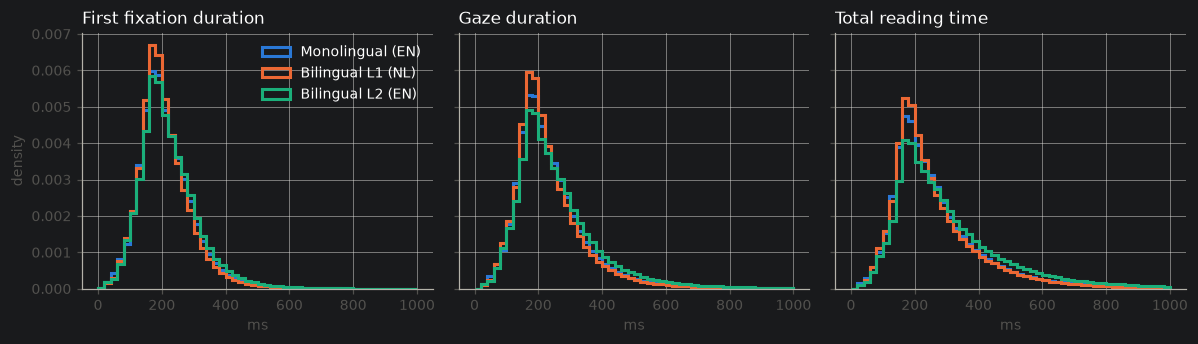

In [36]:
# Distributions of the reading measures per reader group (fixated words only)
measures = {"ffd": "First fixation duration", "gd": "Gaze duration", "trt": "Total reading time"}
bins = np.arange(0, 1001, 20)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, (col, title) in zip(axes, measures.items()):
    for group, color in GROUP_COLORS.items():
        values = rm.filter(pl.col("reader_group") == group)[col].drop_nulls().to_numpy()
        ax.hist(values, bins=bins, density=True, histtype="step", color=color, linewidth=2,
                label=GROUP_LABELS[group])
    ax.set_title(title, loc="left")
    ax.set_xlabel("ms")
axes[0].set_ylabel("density")
axes[0].legend(loc="upper right")
fig.tight_layout()

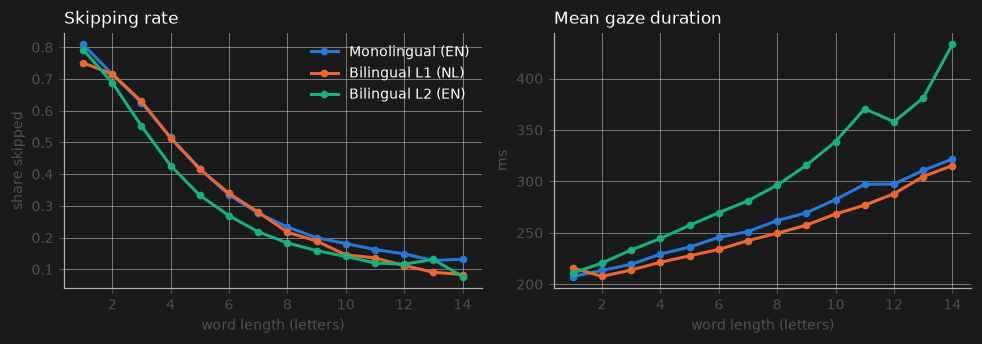

In [37]:
# Word-length effect: longer words should be skipped less and read longer
by_length = (
    rm.filter(pl.col("word_length").is_between(1, 14))
    .group_by("reader_group", "word_length")
    .agg(skip_rate=pl.col("skip").mean(), gd=pl.col("gd").mean())
    .sort("word_length")
)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for group, color in GROUP_COLORS.items():
    d = by_length.filter(pl.col("reader_group") == group)
    axes[0].plot(d["word_length"], d["skip_rate"], color=color, marker="o", markersize=4, label=GROUP_LABELS[group])
    axes[1].plot(d["word_length"], d["gd"], color=color, marker="o", markersize=4)
axes[0].set(title="Skipping rate", xlabel="word length (letters)", ylabel="share skipped")
axes[1].set(title="Mean gaze duration", xlabel="word length (letters)", ylabel="ms")
for ax in axes:
    ax.title.set_ha("left"); ax.title.set_x(0)
axes[0].legend()
fig.tight_layout()

reader_group,participant_id,gd,skip_rate,n_words
str,str,f64,f64,u32
"""bi_L2""","""pp06""",366.936962,0.445019,29956
"""bi_L2""","""pp17""",323.029797,0.219807,26455
"""mono""","""pp30""",300.635784,0.455256,56410
"""bi_L1""","""pp17""",294.378724,0.275831,31842
"""bi_L1""","""pp06""",291.263179,0.406974,28852


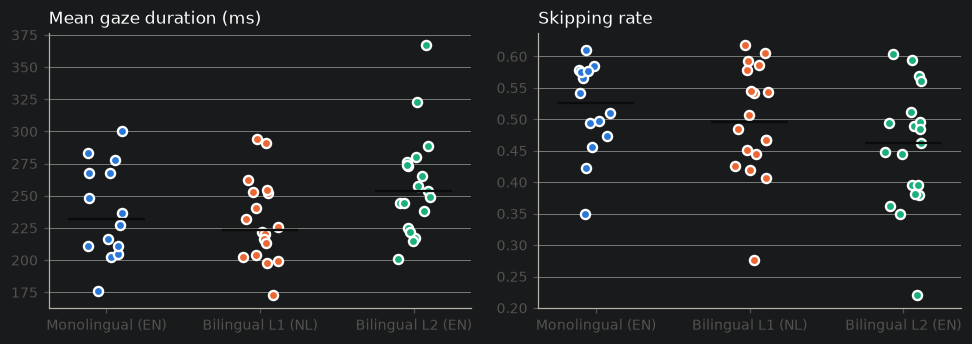

In [38]:
# One dot per participant and group: spot unusual readers
per_pp = (
    rm.group_by("reader_group", "participant_id")
    .agg(gd=pl.col("gd").mean(), skip_rate=pl.col("skip").mean(), n_words=pl.len())
)
groups = list(GROUP_COLORS)
rng = np.random.default_rng(0)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, col, title in [(axes[0], "gd", "Mean gaze duration (ms)"), (axes[1], "skip_rate", "Skipping rate")]:
    for i, group in enumerate(groups):
        d = per_pp.filter(pl.col("reader_group") == group)[col].to_numpy()
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d, s=36, color=GROUP_COLORS[group],
                   edgecolor="white", linewidth=1.5, zorder=3)
        ax.hlines(np.median(d), i - 0.25, i + 0.25, color="#0b0b0b", linewidth=1.5, zorder=4)
    ax.set_xticks(range(len(groups)), [GROUP_LABELS[g] for g in groups])
    ax.set_title(title, loc="left")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
per_pp.sort("gd", descending=True).head(5)

## 2. GECO x SWOW cross-reference (English)

`match_type` says how a word was found among the SWOW cues: exact `form`, `form_lower`, spaCy `lemma`,
`case_fold`; `response_only` = only occurs as a SWOW response (node without outgoing edges); `none` = not in SWOW.

In [39]:
content_en = words_en.filter(
    (pl.col("is_content_word") | pl.col("is_proper_noun")) & (pl.col("match_type") != "punctuation")
)
content_en.select("word_id", "word", "form", "lemma", "spacy_pos", "match_type", "swow_cue").head(15)

word_id,word,form,lemma,spacy_pos,match_type,swow_cue
str,str,str,str,str,str,str
"""1-5-2""","""intense""","""intense""","""intense""","""ADJ""","""form""","""intense"""
"""1-5-3""","""interest""","""interest""","""interest""","""NOUN""","""form""","""interest"""
"""1-5-4""","""aroused""","""aroused""","""arouse""","""VERB""","""lemma""","""arouse"""
"""1-5-7""","""public""","""public""","""public""","""NOUN""","""form""","""public"""
"""1-5-11""","""known""","""known""","""know""","""VERB""","""form""","""known"""
…,…,…,…,…,…,…
"""1-5-22""","""subsided.""","""subsided""","""subside""","""VERB""","""response_only""",null
"""1-5-23""","""Nevertheless,""","""Nevertheless""","""nevertheless""","""ADV""","""form_lower""","""nevertheless"""
"""1-5-25""","""view""","""view""","""view""","""NOUN""","""form""","""view"""


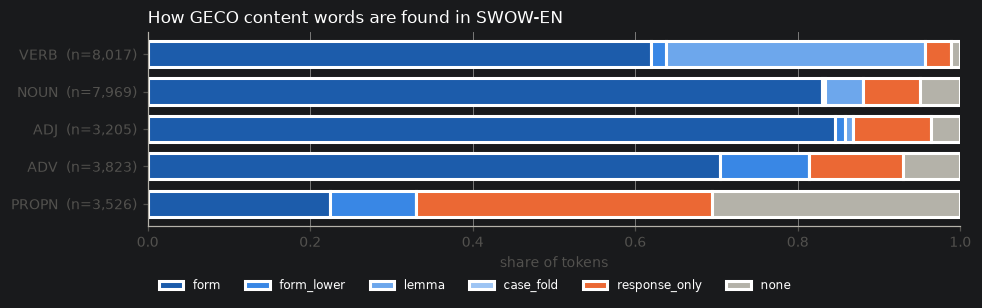

In [40]:
# Share of content-word tokens per match type, by POS
order = list(MATCH_COLORS)
shares = (
    content_en.group_by("spacy_pos", "match_type").len()
    .with_columns(share=pl.col("len") / pl.col("len").sum().over("spacy_pos"))
    .pivot(on="match_type", index="spacy_pos", values="share").fill_null(0)
)
pos_order = ["VERB", "NOUN", "ADJ", "ADV", "PROPN"]
shares = shares.with_columns(pl.col("spacy_pos").replace_strict({p: i for i, p in enumerate(pos_order)}).alias("_o")).sort("_o")
tokens_per_pos = dict(content_en.group_by("spacy_pos").len().iter_rows())

fig, ax = plt.subplots(figsize=(9, 3))
left = np.zeros(shares.height)
for match_type in order:
    if match_type not in shares.columns:
        continue
    values = shares[match_type].to_numpy()
    ax.barh(shares["spacy_pos"], values, left=left, color=MATCH_COLORS[match_type],
            edgecolor="white", linewidth=2, height=0.7, label=match_type)
    left += values
ax.set_yticks(range(shares.height), [f"{p}  (n={tokens_per_pos[p]:,})" for p in shares["spacy_pos"]])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share of tokens")
ax.set_title("How GECO content words are found in SWOW-EN", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(ncol=6, loc="upper left", bbox_to_anchor=(0, -0.22), fontsize=8)
fig.tight_layout()

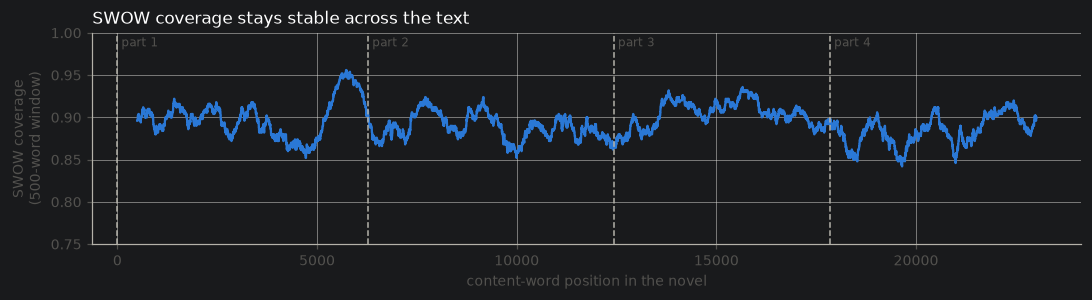

In [41]:
# Coverage along the novel: rolling share of content words that are SWOW cues
content_only = words_en.filter(pl.col("is_content_word")).with_row_index("i")
window = 500
rolling = content_only.with_columns(cov=pl.col("in_swow").cast(pl.Float64).rolling_mean(window))
part_starts = content_only.group_by("part").agg(pl.col("i").min()).sort("part")

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(rolling["i"], rolling["cov"], color=GROUP_COLORS["mono"], linewidth=1.5)
for part, start in part_starts.iter_rows():
    ax.axvline(start, color="#b4b2a9", linewidth=1, linestyle="--")
    ax.text(start, 0.995, f" part {part}", va="top", fontsize=8, color=TEXT_SECONDARY)
ax.set(ylim=(0.75, 1), xlabel="content-word position in the novel",
       ylabel=f"SWOW coverage\n({window}-word window)")
ax.set_title("SWOW coverage stays stable across the text", loc="left")
fig.tight_layout()

The intense interest aroused in the public by what was known at the time as 'The Styles* Case'* has now somewhat [subsided.] Nevertheless, in view of the [world-wide] [notoriety] which attended it, I have been asked, both by my friend Poirot* and the family themselves, to write an account of the whole story. This, we trust, will [effectually] silence the [sensational] [rumours] which still persist. I will therefore [briefly] set down the circumstances which led to my being connected with the affair.


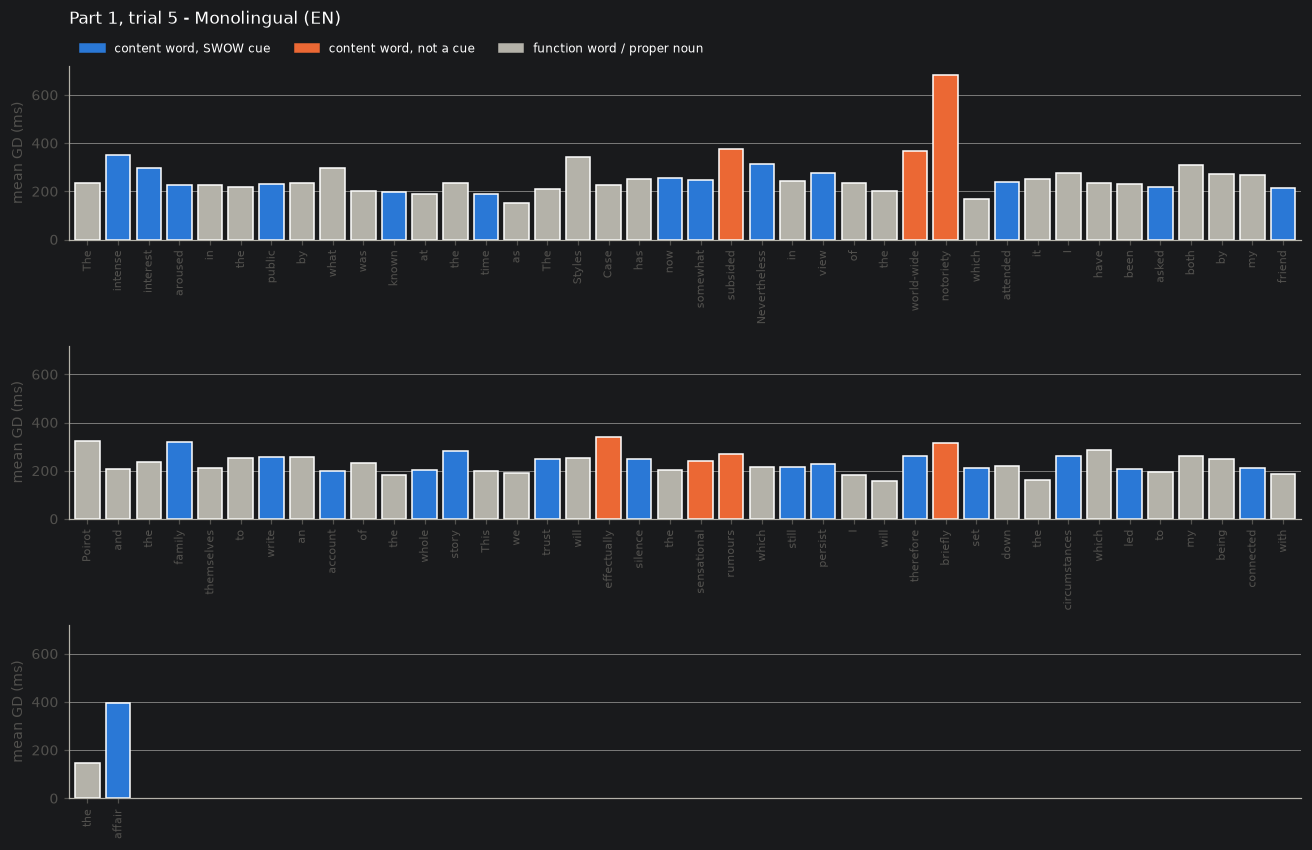

In [42]:
def show_trial(part: int, trial: int, reader_group: str = "mono") -> None:
    """Print one GECO screen with SWOW status marked, and plot mean gaze duration per word.

    In the text: [word] = content word not a SWOW cue, word* = proper noun.
    Long screens (~100 words) are split over several rows of bars.
    """
    from matplotlib.patches import Patch
    w = words_en.filter((pl.col("part") == part) & (pl.col("trial") == trial)).sort("position")
    gd = (rm.filter((pl.col("reader_group") == reader_group) & pl.col("word_id").is_in(w["word_id"].implode()))
          .group_by("word_id").agg(gd=pl.col("gd").mean()))
    w = w.join(gd, on="word_id", how="left")

    tokens = []
    for word, content, propn, in_swow in w.select("word", "is_content_word", "is_proper_noun", "in_swow").iter_rows():
        if propn:
            tokens.append(word + "*")
        elif content and not in_swow:
            tokens.append(f"[{word}]")
        else:
            tokens.append(word)
    print(" ".join(tokens))

    colors = [
        ("#2a78d6" if s else "#eb6834") if c else "#b4b2a9"
        for c, s in w.select("is_content_word", "in_swow").iter_rows()
    ]
    per_row = 40
    n_rows = int(np.ceil(w.height / per_row))
    gd_max = w["gd"].max() * 1.05
    fig, axes = plt.subplots(n_rows, 1, figsize=(12, 2.6 * n_rows), squeeze=False)
    for r, ax in enumerate(axes[:, 0]):
        chunk = w.slice(r * per_row, per_row)
        ax.bar(range(chunk.height), chunk["gd"].fill_null(0), color=colors[r * per_row:(r + 1) * per_row],
               edgecolor="white", linewidth=1)
        ax.set_xticks(range(chunk.height), chunk["form"], rotation=90, fontsize=7)
        ax.set_xlim(-0.6, per_row - 0.4)
        ax.set_ylim(0, gd_max)
        ax.set_ylabel("mean GD (ms)")
        ax.grid(axis="x", visible=False)
    axes[0, 0].set_title(f"Part {part}, trial {trial} - {GROUP_LABELS[reader_group]}", loc="left", pad=28)
    axes[0, 0].legend(handles=[Patch(color="#2a78d6", label="content word, SWOW cue"),
                               Patch(color="#eb6834", label="content word, not a cue"),
                               Patch(color="#b4b2a9", label="function word / proper noun")],
                      ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8)
    fig.tight_layout()

show_trial(part=1, trial=5)

In [43]:
# Most frequent content words that are not SWOW cues
(content_en.filter(pl.col("is_content_word") & ~pl.col("in_swow"))
 .group_by(pl.col("form").str.to_lowercase().alias("form"))
 .agg(tokens=pl.len(), lemma=pl.col("lemma").first(), pos=pl.col("spacy_pos").mode().first(),
      match_type=pl.col("match_type").first())
 .sort("tokens", descending=True)
 .head(20))

form,tokens,lemma,pos,match_type
str,u32,str,str,str
"""strychnine""",65,"""strychnine""","""NOUN""","""response_only"""
"""ami""",29,"""ami""","""NOUN""","""response_only"""
"""o'clock""",28,"""o'clock""","""NOUN""","""response_only"""
"""boudoir""",24,"""boudoir""","""NOUN""","""response_only"""
"""inquest""",23,"""inquest""","""NOUN""","""response_only"""
…,…,…,…,…
"""utterly""",10,"""utterly""","""ADV""","""response_only"""
"""earnestly""",10,"""earnestly""","""ADV""","""response_only"""
"""bromide""",10,"""bromide""","""NOUN""","""none"""


## 3. The SWOW-EN network

Directed cue -> response edges, weighted by association strength. Only cues have outgoing edges, so the
out-degree is bounded by the number of distinct responses per cue; the in-degree is heavy-tailed.

nodes: 133,763, cues: 12,217, edges: 1,389,711


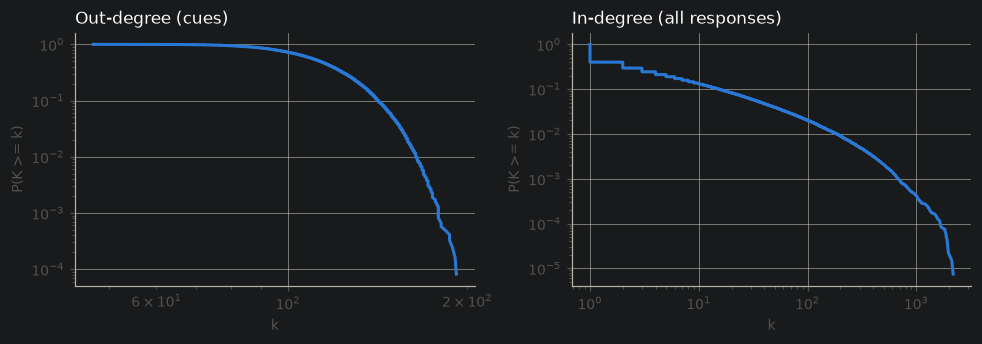

In [44]:
out_degree = strength_en.group_by("cue").agg(k_out=pl.len(), s_out=pl.col("strength").sum())
in_degree = strength_en.group_by("response").agg(k_in=pl.len(), s_in=pl.col("strength").sum())
print(f"nodes: {pl.concat([strength_en['cue'], strength_en['response']]).n_unique():,}, "
      f"cues: {out_degree.height:,}, edges: {strength_en.height:,}")

def ccdf(values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    x = np.sort(values)
    return x, 1.0 - np.arange(len(x)) / len(x)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, values, title in [(axes[0], out_degree["k_out"].to_numpy(), "Out-degree (cues)"),
                          (axes[1], in_degree["k_in"].to_numpy(), "In-degree (all responses)")]:
    x, y = ccdf(values)
    ax.loglog(x, y, color=GROUP_COLORS["mono"], linewidth=2)
    ax.set(xlabel="k", ylabel="P(K >= k)")
    ax.set_title(title, loc="left")
fig.tight_layout()

In [45]:
import networkx as nx
from matplotlib.colors import Normalize


def visualize_degree_distribution(G, name, n_labels=30, node_size=25):
    """Draw the largest connected component of G, coloured by degree, above a degree histogram.

    Only the `n_labels` highest-degree nodes get a label. Use a small subgraph: the layout
    gets slow and the drawing unreadable beyond a few thousand edges.
    """
    measure = "Degree"
    Gcc = G.subgraph(max(nx.connected_components(G), key=len))
    node_degrees = dict(Gcc.degree())

    degree_sequence = sorted(node_degrees.values(), reverse=True)
    degree_norm = Normalize(vmin=min(degree_sequence), vmax=max(degree_sequence))
    degree_cmap = plt.cm.Blues

    fig = plt.figure(f"Degree of a {name} Graph", figsize=(10, 10), facecolor="grey")
    # Create a gridspec for adding subplots of different sizes
    axgrid = fig.add_gridspec(5, 4)

    ax0 = fig.add_subplot(axgrid[0:3, :])
    pos = nx.spring_layout(Gcc, seed=10396953)
    nx.draw_networkx_nodes(
        Gcc, pos, ax=ax0, node_size=node_size,
        node_color=[node_degrees[node] for node in Gcc.nodes],
        cmap=degree_cmap, vmin=degree_norm.vmin, vmax=degree_norm.vmax,
    )
    nx.draw_networkx_edges(Gcc, pos, ax=ax0, alpha=0.4, width=0.5, edge_color="orange")
    hubs = sorted(node_degrees, key=node_degrees.get, reverse=True)[:n_labels]
    nx.draw_networkx_labels(Gcc, pos, labels={node: node for node in hubs}, ax=ax0, font_size=7)
    ax0.set_title(f"Largest connected component of {name} graph "
                  f"({Gcc.number_of_nodes():,} nodes, {Gcc.number_of_edges():,} edges)")
    ax0.set_axis_off()

    ax2 = fig.add_subplot(axgrid[3:, :], facecolor="grey")
    degrees, counts = np.unique(degree_sequence, return_counts=True)
    p = ax2.bar(degrees, counts, color=degree_cmap(degree_norm(degrees)))
    if len(degrees) <= 12:  # percentages only fit on a few bars
        ax2.bar_label(p, labels=[f'{count/len(node_degrees)*100: .2f}%' for count in counts], label_type="center", color="black")
    ax2.set_title(f"{measure} Histogram")
    ax2.set_xlabel(f"{measure}")
    ax2.set_ylabel("Number of Nodes")
    fig.colorbar(
        plt.cm.ScalarMappable(norm=degree_norm, cmap=degree_cmap),
        ax=ax0, label=f"Node {measure}",
    )

    fig.tight_layout()
    plt.show()


In [46]:
def visualize_network(G, name):
    fig, ax = plt.subplots(figsize=(15, 9), facecolor="grey")
    ax.axis("off")
    plot_options = {"node_size": 300, "with_labels": True, "width": 0.15, "edge_color": "orange", "alpha": 0.9}
    nx.draw_networkx(G, pos=nx.spring_layout(G, seed=10396953), ax=ax, **plot_options)
    ax.set_title(f"{name} Graph", fontsize=16)


### Drawing the network

The full network (134k nodes, 1.39M edges) can't be drawn, so these plots show readable subgraphs:
the strongest associations between hub cues, and the neighbourhood of a single word. Both are
undirected and only contain SWOW cues. They are for inspection: community detection uses the full graph.

In [55]:
cue_list = out_degree["cue"].to_list()
cue_edges = strength_en.filter(pl.col("response").is_in(cue_list) & (pl.col("cue") != pl.col("response")))


def strongest_edges_graph(edges: pl.DataFrame, k: int = 3) -> nx.Graph:
    """Undirected graph with each cue's k strongest associations."""
    top = edges.sort("strength", descending=True).group_by("cue", maintain_order=True).head(k)
    G = nx.Graph()
    G.add_weighted_edges_from(top.select("cue", "response", "strength").rows())
    return G


def ego_network(edges: pl.DataFrame, word: str, n_neighbours: int = 20, min_strength: float = 0.02) -> nx.Graph:
    """`word`, its strongest associates, and the associations among them."""
    neighbours = edges.filter(pl.col("cue") == word).sort("strength", descending=True).head(n_neighbours)
    nodes = [word, *neighbours["response"].to_list()]
    within = edges.filter(pl.col("cue").is_in(nodes) & pl.col("response").is_in(nodes)
                          & (pl.col("strength") >= min_strength))
    G = nx.Graph()
    G.add_weighted_edges_from(within.select("cue", "response", "strength").rows())
    return G

In [56]:
# The 120 best-connected cues, each with its 3 strongest associations among them
hubs = in_degree.filter(pl.col("response").is_in(cue_list)).sort("k_in", descending=True).head(120)["response"].to_list()
hub_edges = cue_edges.filter(pl.col("cue").is_in(hubs) & pl.col("response").is_in(hubs))

In [57]:
strongest_hub_edges_graph = strongest_edges_graph(hub_edges, k=3)

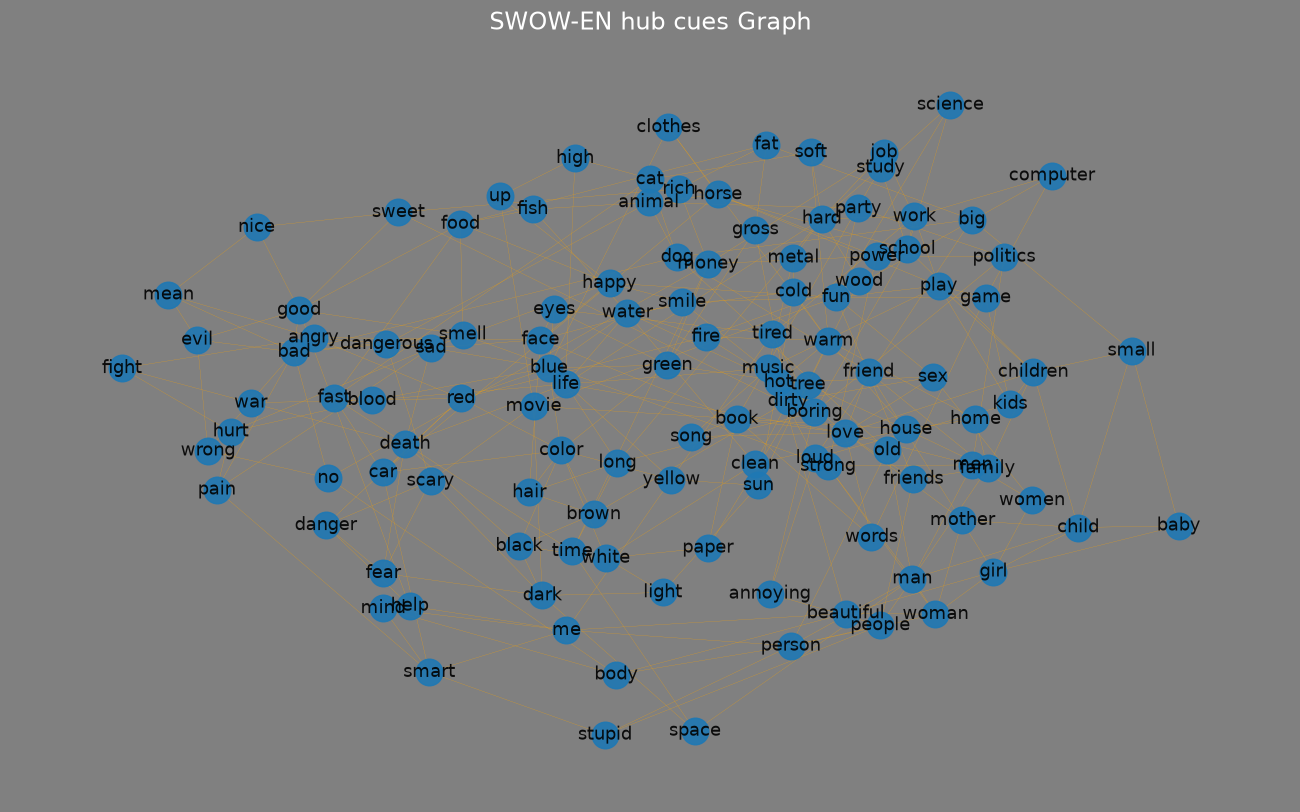

In [58]:
visualize_network(strongest_hub_edges_graph,"SWOW-EN hub cues")

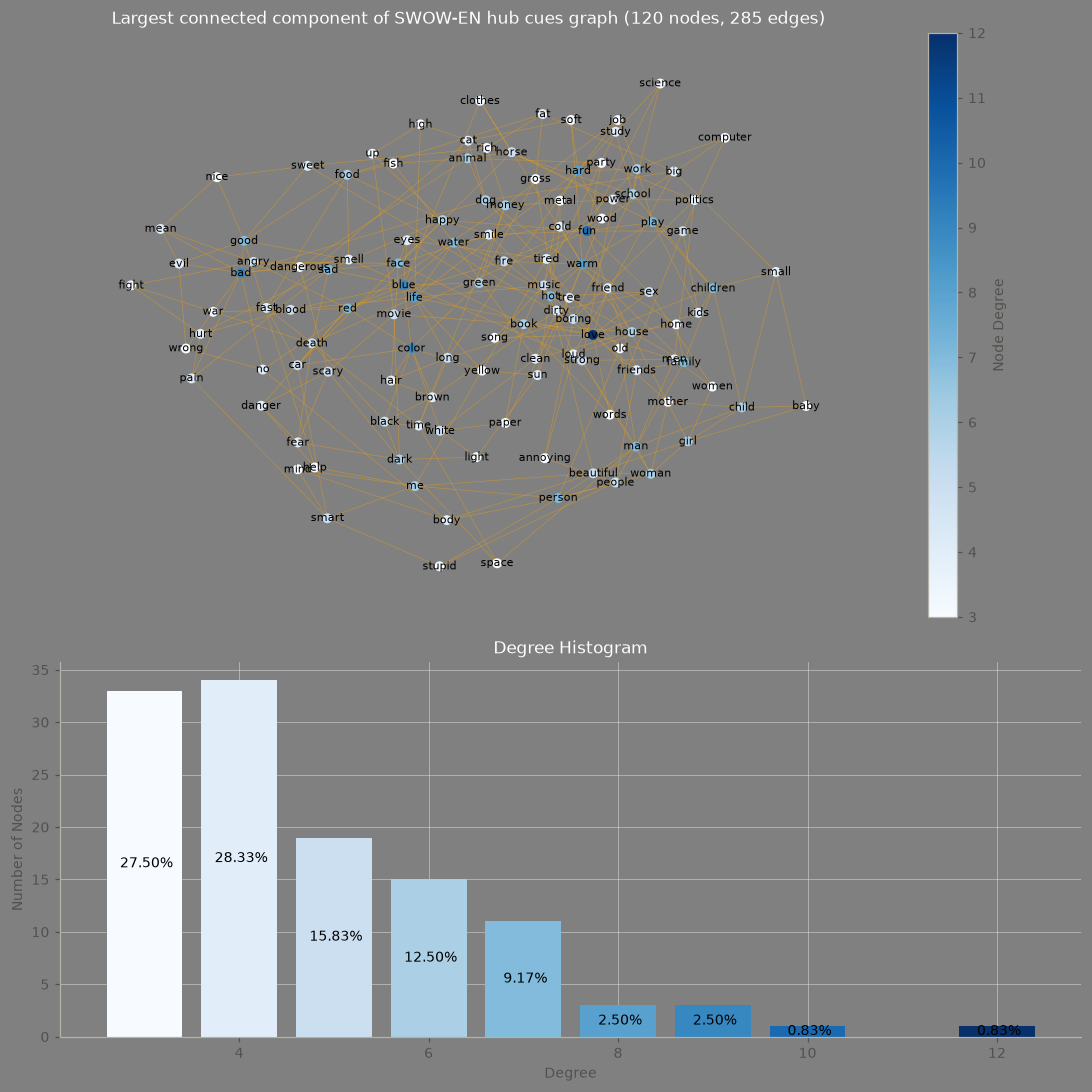

In [59]:

visualize_degree_distribution(strongest_hub_edges_graph, "SWOW-EN hub cues", n_labels=120, node_size=30)

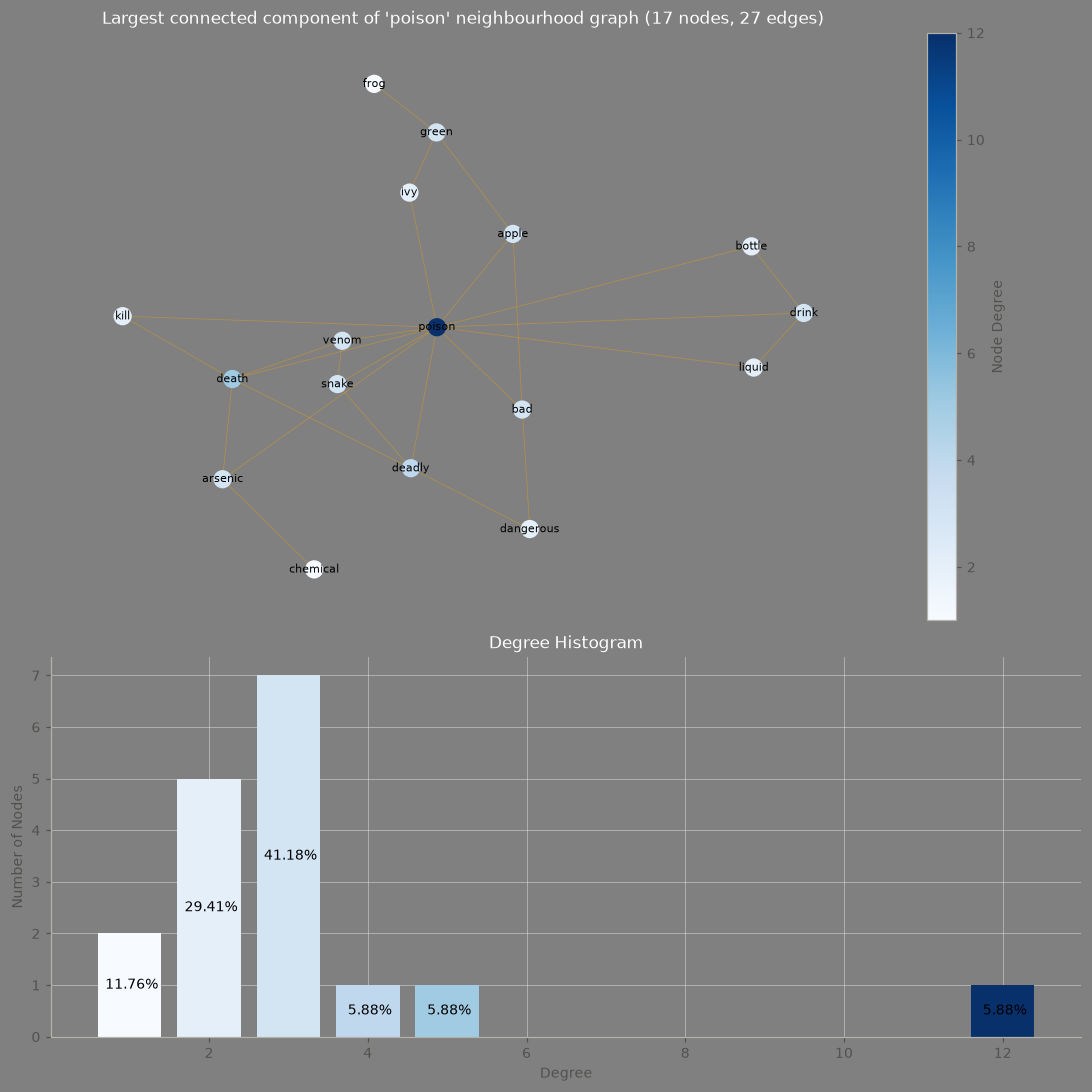

In [60]:
# Neighbourhood of one word from the novel: change `word` to explore
word = "poison"
visualize_degree_distribution(ego_network(cue_edges, word), f"'{word}' neighbourhood", n_labels=25, node_size=120)